# Movie Genre Prediction with a Multi-Layer Perceptron

Issue #37 · Multi-label classification · Steps 1–12

## Data and goal

Source: `data/features/10_genre_features.csv` from the shared Week 5 Features folder. A movie may have multiple genre labels.

## 1. Select input features and genre targets

Use 15 numeric or Boolean features and original language as inputs. Predict 20 binary genre columns; a movie can have more than one genre. Exclude `id` and all genre labels from the inputs, plus post-release revenue and popularity. Long text and names need additional encoding, so this first model uses their prepared counts and indicators. Remove rows with no recorded genre rather than treating missing labels as confirmed negatives.

In [1]:
from pathlib import Path
import pandas as pd

# Find the CSV whether VS Code starts the notebook in the project root
# or in the notebook's own folder.
relative_path = Path("data/features/10_genre_features.csv")
csv_path = next(
    (folder / relative_path for folder in [Path.cwd(), *Path.cwd().parents]
     if (folder / relative_path).exists()),
    None,
)

if csv_path is None:
    raise FileNotFoundError(
        "Put 10_genre_features.csv in the project's data/features folder."
    )

movies = pd.read_csv(csv_path, low_memory=False)

# These 20 columns are the answers the model should predict.
genre_columns = [
    "Drama", "Crime", "Comedy", "Action", "Thriller",
    "Adventure", "Science Fiction", "Animation", "Family",
    "Romance", "Mystery", "Music", "Horror", "Fantasy",
    "Documentary", "War", "Western", "History", "Foreign", "TV Movie",
]

# Start with movie information that is usable around release time.
numeric_columns = [
    "release_year", "release_month", "log_budget", "runtime",
    "cast_size", "crew_size", "company_count", "country_count",
    "spoken_languages_count", "keyword_count", "title_word_count",
    "overview_word_count", "has_collection", "has_director",
    "title_differs_from_original",
]
categorical_columns = ["original_language"]
feature_columns = numeric_columns + categorical_columns

# Check that the CSV has the columns we expect and that genre labels are 0 or 1.
required_columns = feature_columns + genre_columns
missing_columns = sorted(set(required_columns) - set(movies.columns))
if missing_columns:
    raise ValueError(f"Missing expected columns: {missing_columns}")

if not movies[genre_columns].isin([0, 1]).all().all():
    raise ValueError("Some genre labels are not 0 or 1.")

# Rows with no recorded genre cannot teach the model a known genre.
has_recorded_genre = movies[genre_columns].sum(axis=1) > 0
X = movies.loc[has_recorded_genre, feature_columns].copy()
y = movies.loc[has_recorded_genre, genre_columns].astype(int).copy()

print(f"CSV: {csv_path}")
print(f"All movies: {len(movies):,}")
print(f"Movies with no recorded genre removed: {(~has_recorded_genre).sum():,}")
print(f"Movies available for modeling: {len(X):,}")
print(f"Input features ({len(feature_columns)}): {feature_columns}")
print(f"Genre targets ({len(genre_columns)}): {genre_columns}")
print("\nNumber of movies in each genre:")
print(y.sum().sort_values(ascending=False).to_string())

CSV: /Users/kevinphon/Desktop/DS-ML Project Fall Semester/css-dsml-fall2027/data/features/10_genre_features.csv
All movies: 45,433
Movies with no recorded genre removed: 2,442
Movies available for modeling: 42,991
Input features (16): ['release_year', 'release_month', 'log_budget', 'runtime', 'cast_size', 'crew_size', 'company_count', 'country_count', 'spoken_languages_count', 'keyword_count', 'title_word_count', 'overview_word_count', 'has_collection', 'has_director', 'title_differs_from_original', 'original_language']
Genre targets (20): ['Drama', 'Crime', 'Comedy', 'Action', 'Thriller', 'Adventure', 'Science Fiction', 'Animation', 'Family', 'Romance', 'Mystery', 'Music', 'Horror', 'Fantasy', 'Documentary', 'War', 'Western', 'History', 'Foreign', 'TV Movie']

Number of movies in each genre:
Drama              20244
Comedy             13176
Thriller            7619
Romance             6730
Action              6592
Horror              4671
Crime               4304
Documentary         3

## 2. Prepare numerical and categorical features

Treat zero log budgets as unknown, convert Boolean inputs to 0/1, fill missing numeric values with medians, scale numeric inputs, and one-hot encode original language. The preprocessing pipeline is defined here and fitted on training movies only after the split.

In [2]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Keep the original X from Step 1 intact.
X_model = X.copy()

# The three true/false columns become 1.0/0.0 along with the other numbers.
X_model[numeric_columns] = X_model[numeric_columns].astype(float)

# In this dataset, budget 0 often stands for an unknown budget.
# Treat it as missing so the model does not assume every 0 means a real $0 budget.
zero_budget_count = X_model["log_budget"].eq(0).sum()
X_model["log_budget"] = X_model["log_budget"].mask(
    X_model["log_budget"].eq(0)
)

numeric_preprocessing = Pipeline([
    ("fill_missing", SimpleImputer(strategy="median", add_indicator=True)),
    ("scale", StandardScaler()),
])

categorical_preprocessing = Pipeline([
    ("fill_missing", SimpleImputer(strategy="most_frequent")),
    ("one_hot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ("numbers", numeric_preprocessing, numeric_columns),
    ("language", categorical_preprocessing, categorical_columns),
])

print(f"Zero budgets treated as missing: {zero_budget_count:,}")
print("\nColumns with the most missing values:")
print(X_model.isna().sum().sort_values(ascending=False).head(8).to_string())
print("\nPreprocessing pipeline created. It has not been fitted yet.")

Zero budgets treated as missing: 34,169

Columns with the most missing values:
log_budget           34169
runtime                182
release_year            29
release_month           29
original_language       10
cast_size                0
crew_size                0
company_count            0

Preprocessing pipeline created. It has not been fitted yet.


## 3. Create training, validation, and test splits

Use a fixed seed for an 80/10/10 split. Fit preprocessing on training movies; only transform validation and test movies. Reserve the test set for one final evaluation after selecting a model from validation results.

In [3]:
import numpy as np
from sklearn.model_selection import train_test_split

# First reserve 20% of movies for validation and testing.
X_train, X_holdout, y_train, y_holdout = train_test_split(
    X_model, y, test_size=0.20, random_state=42
)

# Divide that reserved group equally: 10% validation, 10% test.
X_validation, X_test, y_validation, y_test = train_test_split(
    X_holdout, y_holdout, test_size=0.50, random_state=42
)

# Confirm that each movie is in exactly one group.
assert set(X_train.index).isdisjoint(X_validation.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_validation.index).isdisjoint(X_test.index)

# Learn fill values, scaling, and language categories from training movies only.
X_train_ready = preprocessor.fit_transform(X_train)

# Apply those same learned rules to validation and test movies.
X_validation_ready = preprocessor.transform(X_validation)
X_test_ready = preprocessor.transform(X_test)

assert np.isfinite(X_train_ready).all()
assert np.isfinite(X_validation_ready).all()
assert np.isfinite(X_test_ready).all()

print(f"Training movies:   {len(X_train):,} ({len(X_train) / len(X_model):.0%})")
print(f"Validation movies: {len(X_validation):,} ({len(X_validation) / len(X_model):.0%})")
print(f"Test movies:       {len(X_test):,} ({len(X_test) / len(X_model):.0%})")
print(f"Total model inputs after preprocessing: {X_train_ready.shape[1]}")

# Check that even the less common genres appear in all three groups.
genre_counts = pd.DataFrame({
    "training": y_train.sum(),
    "validation": y_validation.sum(),
    "test": y_test.sum(),
})
print("\nFive least common genres across the splits:")
print(genre_counts.sum(axis=1).sort_values().head(5).index.to_list())
print(genre_counts.loc[genre_counts.sum(axis=1).sort_values().head(5).index])

Training movies:   34,392 (80%)
Validation movies: 4,299 (10%)
Test movies:       4,300 (10%)
Total model inputs after preprocessing: 101

Five least common genres across the splits:
['TV Movie', 'Western', 'War', 'History', 'Music']
          training  validation  test
TV Movie       614          73    79
Western        813         116   113
War           1049         132   141
History       1127         133   138
Music         1289         142   166


## 4. Search more MLP settings

Jasper suggested comparing more networks, especially two- and three-layer ones. This focused grid tries 32 combinations of layer size, regularization, learning rate, and batch size. All use the same training split, Adam solver, and seed. The full suggested grid would be much larger, so this is a bounded follow-up search.


In [4]:
import time
from itertools import product
from sklearn.neural_network import MLPClassifier

layer_options = [(64, 32), (128, 64), (256, 128), (128, 64, 32)]
alpha_options = [0.0001, 0.01]
learning_rate_options = [0.0005, 0.001]
batch_options = [128, 256]

configurations = []
for number, (layers, alpha, learning_rate, batch_size) in enumerate(
    product(layer_options, alpha_options, learning_rate_options, batch_options), start=1
):
    configurations.append({
        "name": f"mlp_{number:02d}",
        "layers": layers,
        "alpha": alpha,
        "learning_rate": learning_rate,
        "batch_size": batch_size,
    })

trained_models = {}
training_summary = []
print(f"Training {len(configurations)} MLP configurations")

for config in configurations:
    start_time = time.perf_counter()
    model = MLPClassifier(
        hidden_layer_sizes=config["layers"],
        alpha=config["alpha"],
        learning_rate_init=config["learning_rate"],
        batch_size=config["batch_size"],
        activation="relu",
        solver="adam",
        max_iter=120,
        tol=0.001,
        n_iter_no_change=10,
        random_state=42,
    )
    model.fit(X_train_ready, y_train)
    trained_models[config["name"]] = model
    training_summary.append({
        "model": config["name"],
        "hidden_layers": str(config["layers"]),
        "alpha": config["alpha"],
        "learning_rate": config["learning_rate"],
        "batch_size": config["batch_size"],
        "iterations": model.n_iter_,
        "final_training_loss": model.loss_,
        "training_seconds": round(time.perf_counter() - start_time, 1),
    })
    print(f"{config['name']}: layers={config['layers']}, alpha={config['alpha']}, "
          f"rate={config['learning_rate']}, batch={config['batch_size']}, "
          f"iterations={model.n_iter_}, seconds={training_summary[-1]['training_seconds']}", flush=True)

training_summary = pd.DataFrame(training_summary)
display(training_summary)


Training 32 MLP configurations


mlp_01: layers=(64, 32), alpha=0.0001, rate=0.0005, batch=128, iterations=120, seconds=10.6


/Users/kevinphon/Desktop/DS-ML Project Fall Semester/css-dsml-fall2027/.venv/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (120) reached and the optimization hasn't converged yet.
  warnings.warn(


mlp_02: layers=(64, 32), alpha=0.0001, rate=0.0005, batch=256, iterations=120, seconds=9.2


/Users/kevinphon/Desktop/DS-ML Project Fall Semester/css-dsml-fall2027/.venv/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (120) reached and the optimization hasn't converged yet.
  warnings.warn(


mlp_03: layers=(64, 32), alpha=0.0001, rate=0.001, batch=128, iterations=120, seconds=17.5


... (56 outputs left out)

/Users/kevinphon/Desktop/DS-ML Project Fall Semester/css-dsml-fall2027/.venv/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (120) reached and the optimization hasn't converged yet.
  warnings.warn(


mlp_32: layers=(128, 64, 32), alpha=0.01, rate=0.001, batch=256, iterations=120, seconds=20.1


/Users/kevinphon/Desktop/DS-ML Project Fall Semester/css-dsml-fall2027/.venv/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (120) reached and the optimization hasn't converged yet.
  warnings.warn(


,model,hidden_layers,alpha,learning_rate,batch_size,iterations,final_training_loss,training_seconds
0,mlp_01,"(64, 32)",0.0001,0.0005,128,120,4.841768,10.6
1,mlp_02,"(64, 32)",0.0001,0.0005,256,120,4.870620,9.2
2,mlp_03,"(64, 32)",0.0001,0.0010,128,120,4.810258,17.5
3,mlp_04,"(64, 32)",0.0001,0.0010,256,120,4.815764,34.5
4,mlp_05,"(64, 32)",0.0100,0.0005,128,120,4.869209,37.2
5,mlp_06,"(64, 32)",0.0100,0.0005,256,120,4.884597,39.3
6,mlp_07,"(64, 32)",0.0100,0.0010,128,120,4.850502,82.0
7,mlp_08,"(64, 32)",0.0100,0.0010,256,120,4.835405,51.9
8,mlp_09,"(128, 64)",0.0001,0.0005,128,120,4.682677,53.5
9,mlp_10,"(128, 64)",0.0001,0.0005,256,120,4.731198,33.1


## 5. Compare model and cutoff combinations on validation data

For each trained model, test the same probability cutoffs on validation movies. Rank combinations by micro F1, with macro F1 as the tie-breaker. Keep the test movies out of this choice.


In [5]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]
validation_rows = []

for config in configurations:
    probabilities = trained_models[config["name"]].predict_proba(X_validation_ready)
    assert probabilities.shape == y_validation.shape
    for threshold in thresholds:
        predictions = (probabilities >= threshold).astype(int)
        validation_rows.append({
            "model": config["name"],
            "hidden_layers": str(config["layers"]),
            "alpha": config["alpha"],
            "learning_rate": config["learning_rate"],
            "batch_size": config["batch_size"],
            "threshold": threshold,
            "micro_precision": precision_score(y_validation, predictions, average="micro", zero_division=0),
            "micro_recall": recall_score(y_validation, predictions, average="micro", zero_division=0),
            "micro_f1": f1_score(y_validation, predictions, average="micro", zero_division=0),
            "macro_f1": f1_score(y_validation, predictions, average="macro", zero_division=0),
            "movies_with_no_predicted_genre": int((predictions.sum(axis=1) == 0).sum()),
        })

validation_grid = pd.DataFrame(validation_rows)
validation_results = (
    validation_grid.sort_values(["micro_f1", "macro_f1"], ascending=False)
    .drop_duplicates("model")
    .reset_index(drop=True)
)
print(f"Compared {len(validation_grid)} model/cutoff combinations on validation movies")
print("Top 10 models at each model's best cutoff:")
display(validation_results.head(10).round(3))


Compared 224 model/cutoff combinations on validation movies
Top 10 models at each model's best cutoff:


,model,hidden_layers,alpha,learning_rate,batch_size,threshold,micro_precision,micro_recall,micro_f1,macro_f1,movies_with_no_predicted_genre
0,mlp_10,"(128, 64)",0.00,0.000,256,0.25,0.431,0.514,0.469,0.286,5
1,mlp_14,"(128, 64)",0.01,0.000,256,0.25,0.430,0.513,0.468,0.284,8
2,mlp_09,"(128, 64)",0.00,0.000,128,0.25,0.432,0.510,0.468,0.293,10
3,mlp_16,"(128, 64)",0.01,0.001,256,0.25,0.424,0.520,0.468,0.294,8
4,mlp_13,"(128, 64)",0.01,0.000,128,0.25,0.433,0.507,0.467,0.287,8
5,mlp_05,"(64, 32)",0.01,0.000,128,0.25,0.439,0.496,0.466,0.276,10
6,mlp_29,"(128, 64, 32)",0.01,0.000,128,0.20,0.389,0.579,0.466,0.311,0
7,mlp_08,"(64, 32)",0.01,0.001,256,0.25,0.437,0.496,0.465,0.278,14
8,mlp_04,"(64, 32)",0.00,0.001,256,0.25,0.434,0.501,0.465,0.278,8
9,mlp_26,"(128, 64, 32)",0.00,0.000,256,0.25,0.428,0.508,0.465,0.285,10


## 6. Choose the model and cutoff from validation results

The highest validation micro F1 determines the model and cutoff together. The full search table is kept in `validation_grid`; only the leading rows are printed.


In [6]:
chosen_row = validation_results.iloc[0]
best_model_name = chosen_row["model"]
best_model = trained_models[best_model_name]
best_threshold = float(chosen_row["threshold"])
threshold_results = validation_grid.loc[
    validation_grid["model"] == best_model_name
].sort_values("threshold").reset_index(drop=True)

print("Chosen settings (validation only):")
display(chosen_row.to_frame().T)
print("Cutoffs for the chosen model:")
display(threshold_results[["threshold", "micro_precision", "micro_recall", "micro_f1", "macro_f1", "movies_with_no_predicted_genre"]].round(3))


Chosen settings (validation only):


,model,hidden_layers,alpha,learning_rate,batch_size,threshold,micro_precision,micro_recall,micro_f1,macro_f1,movies_with_no_predicted_genre
0,mlp_10,"(128, 64)",0.0001,0.0005,256,0.25,0.431358,0.513944,0.469044,0.286028,5


Cutoffs for the chosen model:


,threshold,micro_precision,micro_recall,micro_f1,macro_f1,movies_with_no_predicted_genre
0,0.20,0.383,0.585,0.462,0.303,1
1,0.25,0.431,0.514,0.469,0.286,5
2,0.30,0.476,0.446,0.461,0.262,47
3,0.35,0.518,0.387,0.443,0.237,196
4,0.40,0.556,0.338,0.421,0.216,466
5,0.45,0.595,0.296,0.395,0.191,815
6,0.50,0.628,0.260,0.368,0.170,1171


## 7. Evaluate the chosen model on the test set

The settings above are fixed before this cell. This follow-up reuses the original test split, which was already evaluated in the first notebook version; that limits how independent this new test estimate is. Do not use its scores to choose settings.


In [7]:
# This is the final held-out evaluation. Do not tune settings on these results.
test_probabilities = best_model.predict_proba(X_test_ready)
test_predictions = (test_probabilities >= best_threshold).astype(int)
assert test_predictions.shape == y_test.shape

test_results = {
    "micro_precision": precision_score(
        y_test, test_predictions, average="micro", zero_division=0
    ),
    "micro_recall": recall_score(
        y_test, test_predictions, average="micro", zero_division=0
    ),
    "micro_f1": f1_score(y_test, test_predictions, average="micro", zero_division=0),
    "macro_precision": precision_score(
        y_test, test_predictions, average="macro", zero_division=0
    ),
    "macro_recall": recall_score(
        y_test, test_predictions, average="macro", zero_division=0
    ),
    "macro_f1": f1_score(y_test, test_predictions, average="macro", zero_division=0),
}

print(f"Final test results: {best_model_name}, threshold {best_threshold:.2f}")
for metric, value in test_results.items():
    print(f"{metric}: {value:.3f}")
print(f"Test movies with no predicted genre: {(test_predictions.sum(axis=1) == 0).sum():,} / {len(X_test):,}")

Final test results: mlp_10, threshold 0.25
micro_precision: 0.430
micro_recall: 0.507
micro_f1: 0.465
macro_precision: 0.332
macro_recall: 0.293
macro_f1: 0.282
Test movies with no predicted genre: 6 / 4,300


## 8. Compare the leading model settings

This chart shows the best validation cutoff for each of the top ten models. It is not the final test score.


python(97689) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(97690) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


Matplotlib is building the font cache; this may take a moment.


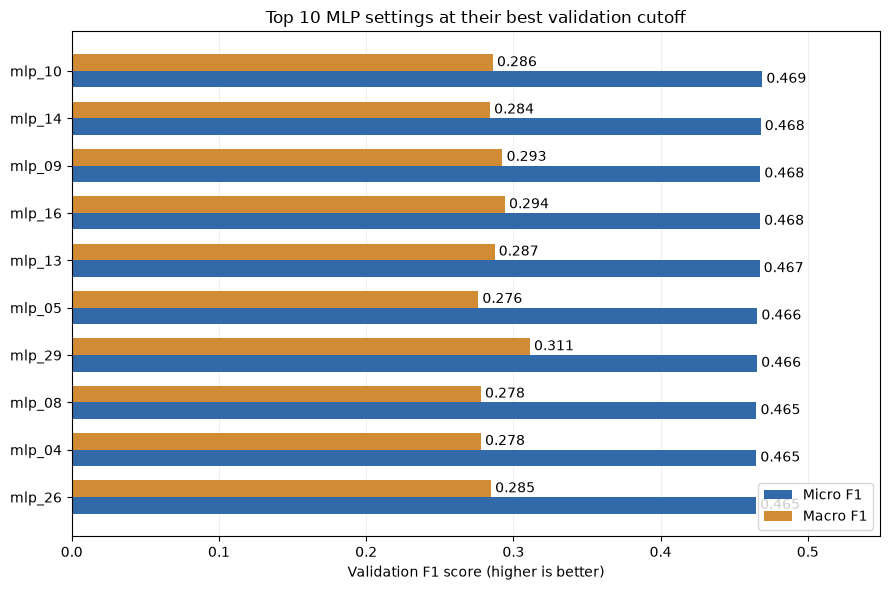

In [8]:
import matplotlib.pyplot as plt

comparison = validation_results.head(10).sort_values("micro_f1")
positions = np.arange(len(comparison))
bar_height = 0.35

fig, ax = plt.subplots(figsize=(9, 6))
micro_bars = ax.barh(positions - bar_height / 2, comparison["micro_f1"],
                    height=bar_height, label="Micro F1", color="#3269a8")
macro_bars = ax.barh(positions + bar_height / 2, comparison["macro_f1"],
                    height=bar_height, label="Macro F1", color="#d18b35")
ax.set_yticks(positions, comparison["model"])
ax.set_xlim(0, max(comparison[["micro_f1", "macro_f1"]].max()) + 0.08)
ax.set_xlabel("Validation F1 score (higher is better)")
ax.set_title("Top 10 MLP settings at their best validation cutoff")
ax.legend()
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.bar_label(micro_bars, fmt="%.3f", padding=3)
ax.bar_label(macro_bars, fmt="%.3f", padding=3)
fig.tight_layout()
plt.show()


## 9. Show F1 for each genre

Use the chosen model’s final test predictions. A separate F1 score for every genre shows where the model works better or worse; the number of actual examples gives context for rare genres.

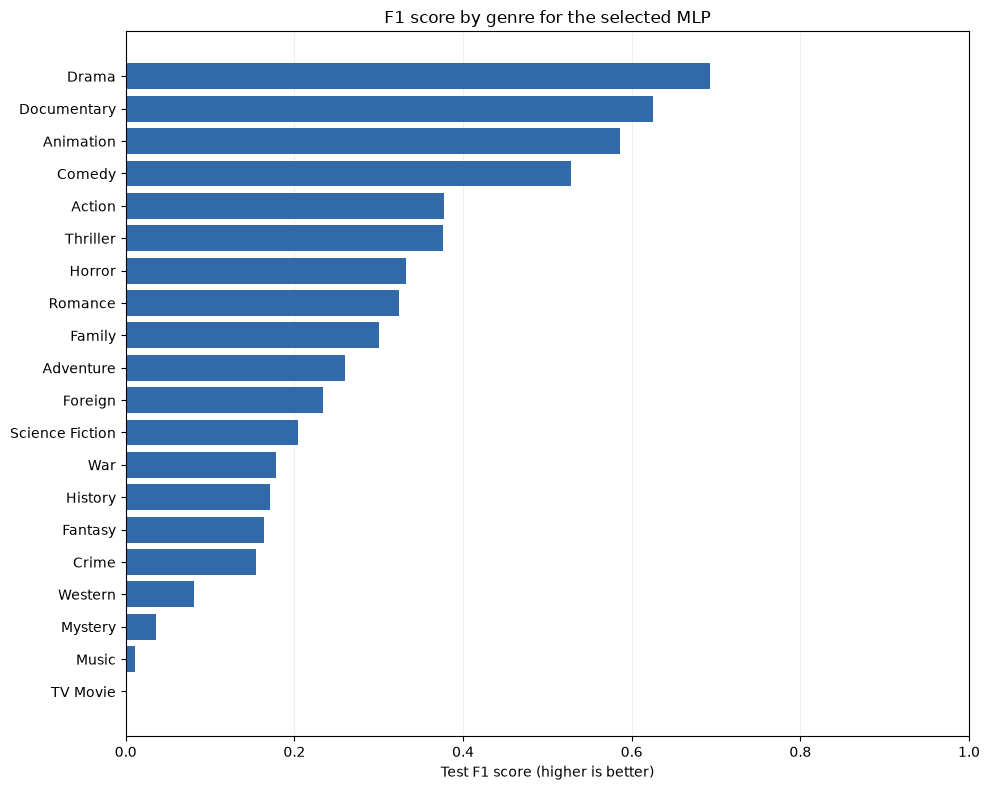

          genre  test_movies_with_genre  precision  recall    f1
       TV Movie                      79      0.000   0.000 0.000
          Music                     166      0.083   0.006 0.011
        Mystery                     243      0.156   0.021 0.036
        Western                     113      0.455   0.044 0.081
          Crime                     407      0.234   0.115 0.155
        Fantasy                     237      0.290   0.114 0.164
        History                     138      0.247   0.130 0.171
            War                     141      0.410   0.113 0.178
Science Fiction                     334      0.311   0.153 0.205
        Foreign                     161      0.254   0.217 0.234
      Adventure                     353      0.360   0.204 0.260
         Family                     270      0.410   0.237 0.300
        Romance                     652      0.287   0.373 0.324
         Horror                     470      0.341   0.326 0.333
       Thriller          

In [9]:
per_genre_results = pd.DataFrame({
    "genre": genre_columns,
    "test_movies_with_genre": y_test.sum(axis=0).to_numpy(),
    "precision": precision_score(
        y_test, test_predictions, average=None, zero_division=0
    ),
    "recall": recall_score(y_test, test_predictions, average=None, zero_division=0),
    "f1": f1_score(y_test, test_predictions, average=None, zero_division=0),
}).sort_values("f1")

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(per_genre_results["genre"], per_genre_results["f1"], color="#3269a8")
ax.set_xlim(0, 1)
ax.set_xlabel("Test F1 score (higher is better)")
ax.set_title("F1 score by genre for the selected MLP")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

print(per_genre_results.to_string(index=False, float_format=lambda value: f"{value:.3f}"))

## 10. Show one movie prediction

Use one held-out movie as a simple inference example. The title is shown only to identify the movie; it was not a model input. The model uses the same preprocessing and threshold chosen earlier.

In [10]:
from IPython.display import display

# Pick the first test movie with at least one predicted genre for a readable demo.
# This sample choice is only for the example; all test movies count in the metrics.
example_position = int(np.flatnonzero(test_predictions.sum(axis=1) > 0)[0])
example_input = X_test.iloc[[example_position]]
example_index = example_input.index[0]
example_probabilities = best_model.predict_proba(
    preprocessor.transform(example_input)
)
example_prediction = (example_probabilities >= best_threshold).astype(int)[0]
example_actual = y_test.loc[example_index].to_numpy()

print(f"Movie: {movies.loc[example_index, 'title']}")
print("Selected input fields:")
display(example_input[[
    "release_year", "release_month", "original_language", "runtime",
    "log_budget", "cast_size", "crew_size", "keyword_count"
]])
print("Predicted genres:", [genre for genre, value in zip(genre_columns, example_prediction) if value])
print("Actual recorded genres:", [genre for genre, value in zip(genre_columns, example_actual) if value])

Movie: Back to Stay
Selected input fields:


,release_year,release_month,original_language,runtime,log_budget,cast_size,crew_size,keyword_count
27591,2011.0,8.0,en,95.0,NaN,4.0,1.0,1.0


Predicted genres: ['Drama', 'Comedy']
Actual recorded genres: ['Drama', 'Comedy']


## 11. Show how cutoff changes validation F1

The chart uses only the selected model's validation results. The vertical line marks the chosen cutoff.


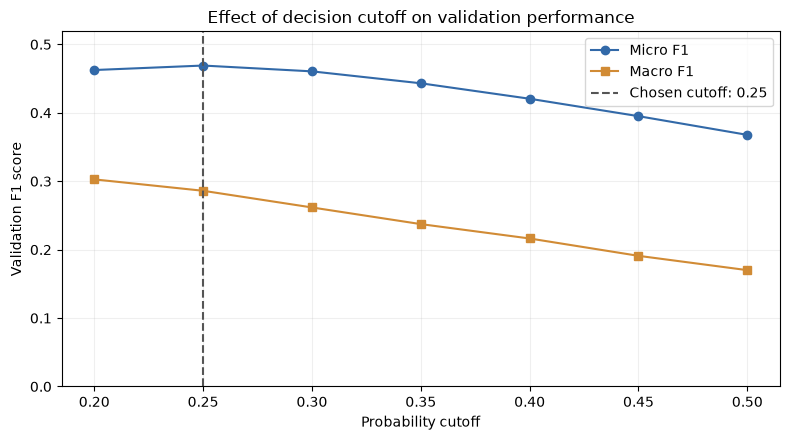

In [11]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(threshold_results["threshold"], threshold_results["micro_f1"],
        marker="o", label="Micro F1", color="#3269a8")
ax.plot(threshold_results["threshold"], threshold_results["macro_f1"],
        marker="s", label="Macro F1", color="#d18b35")
ax.axvline(best_threshold, color="#555555", linestyle="--",
           label=f"Chosen cutoff: {best_threshold:.2f}")
ax.set_xlabel("Probability cutoff")
ax.set_ylabel("Validation F1 score")
ax.set_title("Effect of decision cutoff on validation performance")
ax.set_xticks(threshold_results["threshold"])
ax.set_ylim(0, max(threshold_results[["micro_f1", "macro_f1"]].max()) + 0.05)
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## 12. Explain the updated results

The summary below records the strongest and weakest genres and the final test scores. Training convergence and reuse of the original test split are limitations.


In [12]:
strongest_genres = per_genre_results.sort_values("f1", ascending=False).head(3)
hardest_genres = per_genre_results.sort_values("f1").head(3)

print("Three highest test F1 scores:")
print(strongest_genres[["genre", "test_movies_with_genre", "f1"]].to_string(
    index=False, float_format=lambda value: f"{value:.3f}"
))
print("\nThree lowest test F1 scores:")
print(hardest_genres[["genre", "test_movies_with_genre", "f1"]].to_string(
    index=False, float_format=lambda value: f"{value:.3f}"
))
print(f"\nOverall test micro F1: {test_results['micro_f1']:.3f}; macro F1: {test_results['macro_f1']:.3f}")
print(f"Models at 120-iteration limit: {(training_summary['iterations'] == 120).sum()} / {len(configurations)}")
print("The original test split was evaluated before this expanded search, so interpret this updated test estimate with caution.")


Three highest test F1 scores:
      genre  test_movies_with_genre    f1
      Drama                    2029 0.693
Documentary                     426 0.625
  Animation                     187 0.586

Three lowest test F1 scores:
   genre  test_movies_with_genre    f1
TV Movie                      79 0.000
   Music                     166 0.011
 Mystery                     243 0.036

Overall test micro F1: 0.465; macro F1: 0.282
Models at 120-iteration limit: 32 / 32
The original test split was evaluated before this expanded search, so interpret this updated test estimate with caution.
